# Módulo 14: Tipos de analítica — Solución

> Solución de referencia de la guía [m14-tipos-de-analitica-guia.ipynb](m14-tipos-de-analitica-guia.ipynb). No es una tarea entregada del programa.

Lección del módulo: [m14-tipos-de-analitica-leccion.md](m14-tipos-de-analitica-leccion.md)

## Contexto

**Casa Ámbar** es una tienda en línea de artículos para el hogar que vende y envía a cuatro regiones: Centro, Norte, Occidente y Sur. Hasta ahora, su equipo de datos se limitaba a una hoja de cálculo con las ventas del mes. Al cerrar 2025, la dirección quiere usar mejor sus datos y plantea muchas preguntas a la vez: cuánto se vendió, por qué una de las regiones bajó en el último trimestre, cuánto se venderá en enero y si conviene lanzar un descuento.

Antes de contratar personal, la dirección te pide ordenar esas preguntas: qué **tipo de analítica** requiere cada una y qué **rol** debería responderla. Después te pide responder una pregunta de cada tipo con los datos diarios de ventas de 2025.

Recuerda los cuatro tipos de analítica:

| Tipo | Pregunta que responde |
| --- | --- |
| Descriptiva | ¿Qué pasó? |
| Diagnóstica | ¿Por qué pasó? |
| Predictiva | ¿Qué es probable que pase? |
| Prescriptiva | ¿Qué deberíamos hacer? |

## Datos

La celda inicial genera el DataFrame `ventas`, con una fila por día y región del 1 de enero al 31 de diciembre de 2025:

| Columna | Descripción |
| --- | --- |
| `fecha` | Día |
| `region` | Región de envío: `Centro`, `Norte`, `Occidente` o `Sur` |
| `visitas` | Visitas al sitio desde esa región |
| `pedidos` | Pedidos completados |
| `ingresos` | Ingresos del día en pesos (precio de lista, sin descuentos) |
| `dias_entrega` | Tiempo promedio de entrega de los pedidos del día, en días |

## Instrucciones

1. **Tipo de analítica de cada pregunta.** Clasificar las ocho preguntas de la dirección como descriptiva, diagnóstica, predictiva o prescriptiva, con una justificación.
2. **Rol responsable de cada pregunta.** Asignar a cada pregunta un rol (analista, científico o ingeniero de datos), explicar qué debe construir el ingeniero de datos y elegir el primer rol que contrataría la tienda.
3. **Analítica descriptiva: KPIs mensuales.** Ingresos, pedidos, visitas, ticket promedio y conversión de cada mes.
4. **Analítica diagnóstica: ¿por qué cayó una región?** Identificar la región y el mes, comparar variables antes y después y explicar la causa.
5. **Analítica predictiva: pronóstico de enero de 2026.** Tendencia lineal del ingreso diario promedio y pronóstico de enero.
6. **Analítica prescriptiva: el descuento que maximiza el margen.** Simular el margen con elasticidad 3 y 2 y recomendar un descuento.

La celda siguiente es idéntica a la de la guía: importa las librerías y simula los datos de la tienda con la semilla 42.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

fechas = pd.date_range("2025-01-01", "2025-12-31", freq="D")
regiones = ["Centro", "Norte", "Occidente", "Sur"]
visitas_base = np.array([5200, 3400, 3000, 2600])
entrega_base = np.array([2.6, 3.1, 3.3, 2.9])
entrega_extra = rng.permutation([0.1, 0.0, 3.0, 0.2])
mes_cambio = rng.integers(8, 11)

t = (fechas - fechas[0]).days.to_numpy()
dia_semana = np.array([1.05, 1.0, 0.98, 0.97, 1.0, 0.92, 1.08])[fechas.dayofweek]
partes = []
for i, region in enumerate(regiones):
    visitas = rng.poisson(visitas_base[i] * (1 + 0.0006 * t) * dia_semana)
    cambio = (fechas.month >= mes_cambio) * entrega_extra[i]
    dias_entrega = np.round(entrega_base[i] + cambio + rng.normal(0, 0.3, len(fechas)), 1).clip(1)
    conversion = 0.021 * np.exp(-0.12 * (dias_entrega - 3)) * rng.normal(1, 0.06, len(fechas))
    pedidos = rng.binomial(visitas, conversion.clip(0.001, 0.1))
    ticket = rng.normal(820, 45, len(fechas))
    partes.append(pd.DataFrame({
        "fecha": fechas,
        "region": region,
        "visitas": visitas,
        "pedidos": pedidos,
        "ingresos": np.round(pedidos * ticket, 2),
        "dias_entrega": dias_entrega,
    }))
ventas = pd.concat(partes, ignore_index=True)

print(ventas.shape)
ventas.head()

(1460, 6)


,fecha,region,visitas,pedidos,ingresos,dias_entrega
0,2025-01-01,Centro,5184,107,91685.14,2.9
1,2025-01-02,Centro,4935,105,98402.13,2.6
2,2025-01-03,Centro,5264,117,93959.81,2.3
3,2025-01-04,Centro,4702,122,97525.13,2.3
4,2025-01-05,Centro,5602,154,131608.93,2.7


### Tarea 1. Tipo de analítica de cada pregunta

La clave está en el verbo de la pregunta: *cuánto hubo* (descriptiva), *por qué* (diagnóstica), *cuánto habrá* o *quién hará* (predictiva) y *qué conviene hacer* (prescriptiva).

| # | Pregunta | Tipo | Justificación |
| --- | --- | --- | --- |
| 1 | ¿Cuántos ingresos tendremos en enero de 2026? | Predictiva | Estima un valor futuro a partir de los datos históricos. |
| 2 | ¿Cuántos ingresos, pedidos y visitas tuvimos cada mes de 2025? | Descriptiva | Resume lo que ya pasó; solo requiere agregar los datos. |
| 3 | ¿Qué porcentaje de descuento conviene ofrecer en enero para obtener el mayor margen? | Prescriptiva | Pide elegir la mejor acción entre varias alternativas, según un objetivo (el margen). |
| 4 | ¿Por qué bajaron las ventas de una de las regiones en el último trimestre? | Diagnóstica | Busca la causa de un resultado ya observado. |
| 5 | ¿Cuántos pedidos se están registrando en la última hora en cada región? | Descriptiva | Describe lo que está pasando ahora; que sea en tiempo real no la vuelve predictiva. |
| 6 | ¿Qué clientes tienen alta probabilidad de no volver a comprar en los próximos 90 días? | Predictiva | Estima la probabilidad de un comportamiento futuro de cada cliente (un modelo de abandono). |
| 7 | ¿Las devoluciones aumentaron porque cambiamos de proveedor de textiles? | Diagnóstica | Pone a prueba una explicación causal de un cambio ya ocurrido. |
| 8 | ¿Qué paquetería conviene asignar a cada región para reducir el costo de envío sin pasar de 4 días de entrega? | Prescriptiva | Pide una decisión óptima bajo una restricción, que es un problema de optimización. |

Hay dos preguntas de cada tipo. Los tipos forman una escalera: para prescribir un descuento hace falta predecir cómo responderá la demanda, y para eso hace falta describir y entender las ventas pasadas.

### Tarea 2. Rol responsable de cada pregunta

**1. Rol que encabeza cada pregunta.** Según la lección, el analista de datos hace análisis exploratorios, informes y visualizaciones (Excel, Tableau, SQL); el científico de datos desarrolla modelos estadísticos y de aprendizaje automático para análisis predictivos y prescriptivos (Python, R); y el ingeniero de datos diseña la infraestructura y los *pipelines* que llevan los datos a donde se analizan (Spark, Kafka, Airflow, nube).

| # | Tipo | Rol | Justificación |
| --- | --- | --- | --- |
| 1 | Predictiva | Científico de datos | Requiere ajustar y validar un modelo de pronóstico en Python o R. |
| 2 | Descriptiva | Analista de datos | Es un informe mensual: una consulta SQL y un tablero o una tabla dinámica. |
| 3 | Prescriptiva | Científico de datos | Requiere modelar la respuesta de la demanda al precio y optimizar el margen. |
| 4 | Diagnóstica | Analista de datos | Se resuelve con análisis exploratorio: comparar segmentos y variables antes y después. Si hiciera falta un modelo causal, pediría apoyo al científico. |
| 5 | Descriptiva | Ingeniero de datos | Los pedidos deben llegar en minutos, no al día siguiente: hace falta un flujo de datos en tiempo real (por ejemplo, con Kafka). Después, el analista arma el tablero. |
| 6 | Predictiva | Científico de datos | Es un modelo de clasificación entrenado con el historial de cada cliente. |
| 7 | Diagnóstica | Analista de datos | Compara la tasa de devoluciones antes y después del cambio de proveedor y entre categorías, con una prueba estadística sencilla. |
| 8 | Prescriptiva | Científico de datos | Es un problema de optimización con restricciones (costo frente a tiempo de entrega por región). |

**2. Qué debe construir el ingeniero de datos.** Hoy la tienda solo tiene una hoja de cálculo mensual. Para responder las preguntas 5 a 8 hace falta:

- un **flujo de eventos en tiempo real** que envíe cada pedido a una base analítica en cuanto se confirma (pregunta 5);
- un **almacén de datos** en la nube con el **historial por cliente**: un identificador estable, todas sus compras y visitas, para entrenar el modelo de abandono (pregunta 6);
- la **integración** de los sistemas de devoluciones y de compras, de modo que cada devolución se pueda ligar al producto y a su proveedor (pregunta 7);
- la carga periódica, orquestada con una herramienta como Airflow, de los **costos y tiempos de cada paquetería** por región (pregunta 8).

Sin esta infraestructura, el analista y el científico pasan la mayor parte de su tiempo reuniendo datos a mano.

**3. Primera contratación.** Elegiría a un **analista de datos** con buen dominio de SQL. Cuatro de las ocho preguntas (las descriptivas y las diagnósticas) son de su ámbito y aportan valor de inmediato. Los datos diarios por región ya existen y bastan para un primer pronóstico y una primera simulación sencilla, como las de las tareas 5 y 6. Además, su compensación es la más baja de los tres roles según la tabla de la lección. Sus aptitudes personales encajan con el momento de la empresa: la **atención al detalle** para pasar de una hoja de cálculo a datos confiables, el **pensamiento crítico** para no confundir síntomas con causas (pregunta 4) y la **comunicación eficaz** para convencer a la dirección. Si los datos estuvieran dispersos en muchos sistemas sin acceso directo, en cambio, convendría empezar por un ingeniero de datos, porque sin datos accesibles ninguno de los otros dos roles puede trabajar.

### Tarea 3. Analítica descriptiva: KPIs mensuales

Agregamos por mes los totales y calculamos los dos indicadores derivados. El ticket promedio y la conversión se calculan con los **totales** del mes, no promediando los valores diarios, para que cada pedido y cada visita pesen lo mismo.

In [2]:
ventas["mes"] = ventas["fecha"].dt.month

kpis = ventas.groupby("mes")[["ingresos", "pedidos", "visitas"]].sum()
kpis["ticket_promedio"] = kpis["ingresos"] / kpis["pedidos"]
kpis["conversion_pct"] = 100 * kpis["pedidos"] / kpis["visitas"]

kpis.round({"ingresos": 0, "ticket_promedio": 1, "conversion_pct": 2})

,ingresos,pedidos,visitas,ticket_promedio,conversion_pct
mes,,,,,
1,7816880.0,9486,442918,824.0,2.14
2,7086417.0,8574,408717,826.5,2.10
3,8129780.0,9811,460792,828.6,2.13
4,7875805.0,9575,451764,822.5,2.12
5,8202583.0,9941,473595,825.1,2.10
6,8227574.0,10037,470535,819.7,2.13
7,8559990.0,10418,490893,821.7,2.12
8,8827059.0,10881,500406,811.2,2.17
9,8086859.0,9850,493658,821.0,2.00


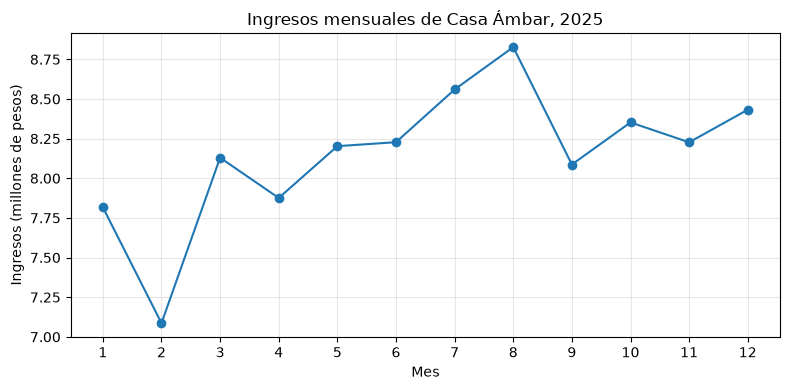

Mes con más ingresos: 8 (8.83 millones)
Mes con menos ingresos: 2 (7.09 millones)
Ingresos del año: 97.82 millones


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kpis.index, kpis["ingresos"] / 1e6, marker="o")
ax.set_title("Ingresos mensuales de Casa Ámbar, 2025")
ax.set_xlabel("Mes")
ax.set_ylabel("Ingresos (millones de pesos)")
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Mes con más ingresos:", kpis["ingresos"].idxmax(), f"({kpis['ingresos'].max() / 1e6:.2f} millones)")
print("Mes con menos ingresos:", kpis["ingresos"].idxmin(), f"({kpis['ingresos'].min() / 1e6:.2f} millones)")
print(f"Ingresos del año: {kpis['ingresos'].sum() / 1e6:.2f} millones")

**Interpretación.** En 2025 la tienda facturó 97.82 millones de pesos. El mes con más ingresos fue agosto (8.83 millones) y el de menos, febrero (7.09 millones), en parte porque tiene solo 28 días. Las visitas crecieron de forma sostenida, de 442 918 en enero a 531 951 en diciembre (+20 %), y el ticket promedio se mantuvo estable, entre 811 y 829 pesos.

Lo que no encaja es la **conversión**: se mantuvo entre 2.10 % y 2.17 % de enero a agosto y bajó a 2.00 % en septiembre y a 1.94 % en diciembre. Por eso los ingresos de septiembre (8.09 millones) quedaron por debajo de los de agosto aunque hubo casi tantas visitas. La analítica descriptiva dice **qué** pasó; para saber **por qué**, hace falta la diagnóstica.

### Tarea 4. Analítica diagnóstica: ¿por qué cayó una región?

Primero, los ingresos mensuales por región y su variación porcentual respecto al mes anterior. La región y el mes de la caída se toman de la mayor caída mensual, no se fijan a mano.

Mayor caída mensual: Norte, mes 9 (-31.7 % frente al mes anterior)


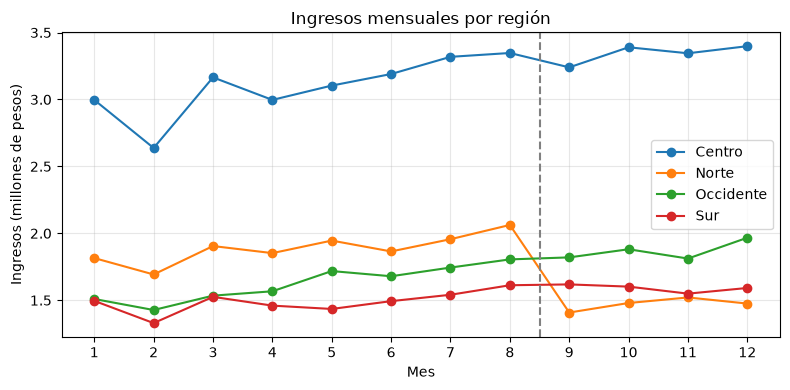

In [4]:
por_region = ventas.pivot_table(index="mes", columns="region", values="ingresos", aggfunc="sum")
variacion = por_region.pct_change() * 100

region_caida = variacion.min().idxmin()
mes_caida = int(variacion[region_caida].idxmin())
print(f"Mayor caída mensual: {region_caida}, mes {mes_caida} "
      f"({variacion.loc[mes_caida, region_caida]:.1f} % frente al mes anterior)")

fig, ax = plt.subplots(figsize=(8, 4))
for region in por_region.columns:
    ax.plot(por_region.index, por_region[region] / 1e6, marker="o", label=region)
ax.axvline(mes_caida - 0.5, color="gray", linestyle="--")
ax.set_title("Ingresos mensuales por región")
ax.set_xlabel("Mes")
ax.set_ylabel("Ingresos (millones de pesos)")
ax.set_xticks(range(1, 13))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Ahora comparamos, en cada región, el periodo anterior a la caída con el posterior. Si la causa fuera general (por ejemplo, menos tráfico en todo el sitio), todas las regiones cambiarían; si es local, solo cambiará la región afectada.

In [5]:
ventas["periodo"] = np.where(ventas["mes"] >= mes_caida, "despues", "antes")

resumen = ventas.groupby(["region", "periodo"]).agg(
    visitas=("visitas", "sum"),
    pedidos=("pedidos", "sum"),
    ingresos=("ingresos", "sum"),
    dias=("fecha", "nunique"),
    dias_entrega=("dias_entrega", "mean"),
)
resumen["visitas_diarias"] = resumen["visitas"] / resumen["dias"]
resumen["conversion_pct"] = 100 * resumen["pedidos"] / resumen["visitas"]
resumen["ticket_promedio"] = resumen["ingresos"] / resumen["pedidos"]

variables = ["visitas_diarias", "conversion_pct", "ticket_promedio", "dias_entrega"]
comparacion = resumen[variables].unstack("periodo")
cambio_pct = (comparacion.xs("despues", axis=1, level="periodo")
              / comparacion.xs("antes", axis=1, level="periodo") - 1) * 100

# Valores de cada variable antes y después de la caída
comparacion.round(2)

visitas_diarias          conversion_pct         ticket_promedio  \
periodo             antes  despues          antes despues           antes   
region                                                                      
Centro            5570.35  6142.57           2.22    2.17          823.45   
Norte             3646.87  4018.20           2.07    1.46          823.58   
Occidente         3215.35  3550.97           2.03    2.09          820.26   
Sur               2792.21  3069.96           2.14    2.09          819.99   

                  dias_entrega          
periodo   despues        antes despues  
region                                  
Centro     821.40         2.59    2.81  
Norte      822.33         3.10    6.05  
Occidente  827.51         3.29    3.32  
Sur        813.89         2.88    3.04

El cambio porcentual de cada variable (después frente a antes) permite comparar las regiones en una sola tabla:

In [6]:
cambio_pct.round(1)

,visitas_diarias,conversion_pct,ticket_promedio,dias_entrega
region,,,,
Centro,10.3,-2.2,-0.2,8.5
Norte,10.2,-29.4,-0.2,95.3
Occidente,10.4,3.0,0.9,0.9
Sur,9.9,-2.4,-0.7,5.8


Por último, la relación entre los días de entrega y la conversión con los datos mensuales de cada región (4 regiones × 12 meses = 48 puntos).

Correlación entre días de entrega y conversión: -0.970
Sin los meses de Norte desde el mes 9 (44 puntos): -0.808


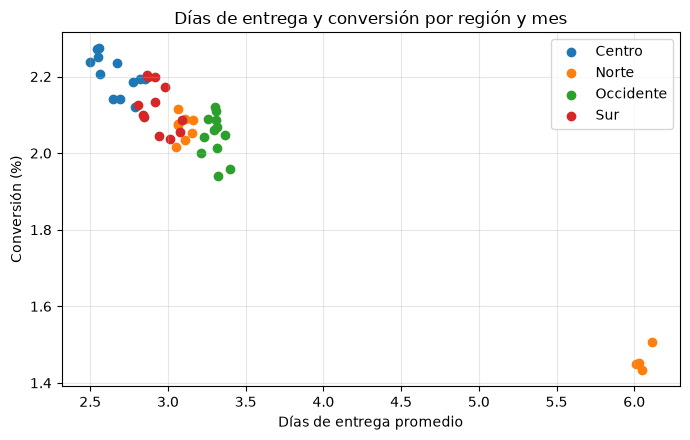

In [7]:
mensual = ventas.groupby(["region", "mes"]).agg(
    visitas=("visitas", "sum"),
    pedidos=("pedidos", "sum"),
    dias_entrega=("dias_entrega", "mean"),
)
mensual["conversion_pct"] = 100 * mensual["pedidos"] / mensual["visitas"]

r = mensual["dias_entrega"].corr(mensual["conversion_pct"])
print(f"Correlación entre días de entrega y conversión: {r:.3f}")

# Comprobación: la misma correlación sin los meses de la región afectada posteriores a la caída
resto = mensual.drop(index=[(region_caida, m) for m in range(mes_caida, 13)])
r_resto = resto["dias_entrega"].corr(resto["conversion_pct"])
print(f"Sin los meses de {region_caida} desde el mes {mes_caida} ({len(resto)} puntos): {r_resto:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
for region, grupo in mensual.groupby(level="region"):
    ax.scatter(grupo["dias_entrega"], grupo["conversion_pct"], label=region)
ax.set_title("Días de entrega y conversión por región y mes")
ax.set_xlabel("Días de entrega promedio")
ax.set_ylabel("Conversión (%)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación.** La región que cayó es **Norte**, a partir de **septiembre** (mes 9): sus ingresos bajaron 31.7 % frente a agosto y se quedaron en ese nivel hasta diciembre. En las otras tres regiones no hay un cambio comparable: sus ingresos de septiembre a diciembre se mantienen en el nivel de los meses anteriores o por encima.

La comparación antes/después descarta dos explicaciones y señala una tercera:

- **Visitas:** no son la causa. Las visitas diarias de Norte crecieron 10.2 %, igual que en las demás regiones (entre 9.9 % y 10.4 %): los clientes siguen llegando al sitio.
- **Ticket promedio:** tampoco. En Norte apenas cambió (−0.2 %): quienes compran gastan lo mismo.
- **Conversión y días de entrega:** aquí está la diferencia. La conversión de Norte cayó de 2.07 % a 1.46 % (−29.4 %), mientras que en las otras regiones varió entre −2.4 % y +3.0 %. En el mismo periodo, sus días de entrega casi se duplicaron, de 3.10 a 6.05 (+95.3 %), frente a cambios de entre 0.9 % y 8.5 % en el resto.

Con los datos mensuales de las cuatro regiones, la correlación entre días de entrega y conversión es −0.970. Este valor está dominado por los cuatro meses de Norte con unos 6 días de entrega, que forman un grupo aparte en el gráfico, pero sin ellos la relación sigue siendo fuerte (−0.808).

**Causa más probable:** a partir de septiembre, las entregas en Norte se volvieron mucho más lentas y muchos clientes abandonan la compra al ver la fecha estimada de entrega. Una correlación no prueba causalidad, así que para confirmarlo pediría: qué cambió en la logística del Norte en septiembre (paquetería, almacén, rutas), la tasa de abandono del carrito en la pantalla de envío por región y las quejas o encuestas de clientes de esa región.

### Tarea 5. Analítica predictiva: pronóstico de enero de 2026

El ingreso diario promedio elimina el efecto de que febrero tenga 28 días y otros meses 31.

In [8]:
diario = ventas.groupby("mes").agg(ingresos=("ingresos", "sum"), dias=("fecha", "nunique"))
diario["ingreso_diario"] = diario["ingresos"] / diario["dias"]

x = diario.index.to_numpy()
y = diario["ingreso_diario"].to_numpy()
pendiente, intercepto = np.polyfit(x, y, deg=1)
r2 = np.corrcoef(x, y)[0, 1] ** 2

pronostico_diario = pendiente * 13 + intercepto
pronostico_enero = pronostico_diario * 31

print(f"Pendiente: {pendiente:,.0f} pesos diarios más por cada mes")
print(f"Intercepto: {intercepto:,.0f}   R²: {r2:.3f}")
print(f"Ingreso diario promedio pronosticado para el mes 13: {pronostico_diario:,.0f}")
print(f"Ingresos pronosticados para enero de 2026 (31 días): {pronostico_enero / 1e6:.2f} millones")
print(f"Ingresos de diciembre de 2025: {diario.loc[12, 'ingresos'] / 1e6:.2f} millones")

Pendiente: 1,945 pesos diarios más por cada mes
Intercepto: 255,269   R²: 0.545
Ingreso diario promedio pronosticado para el mes 13: 280,560
Ingresos pronosticados para enero de 2026 (31 días): 8.70 millones
Ingresos de diciembre de 2025: 8.43 millones


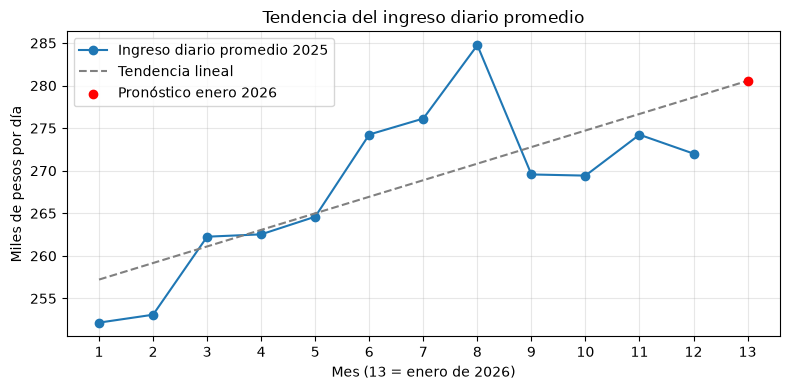

In [9]:
meses = np.arange(1, 14)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y / 1e3, marker="o", label="Ingreso diario promedio 2025")
ax.plot(meses, (pendiente * meses + intercepto) / 1e3, linestyle="--", color="gray", label="Tendencia lineal")
ax.scatter([13], [pronostico_diario / 1e3], color="red", zorder=3, label="Pronóstico enero 2026")
ax.set_title("Tendencia del ingreso diario promedio")
ax.set_xlabel("Mes (13 = enero de 2026)")
ax.set_ylabel("Miles de pesos por día")
ax.set_xticks(meses)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación.** La pendiente indica que el ingreso diario promedio crece unos **1 945 pesos por mes**. La recta pronostica para enero de 2026 un ingreso diario de 280 560 pesos, es decir, unos **8.70 millones** en 31 días, por encima de los 8.43 millones de diciembre.

Este pronóstico tiene limitaciones importantes:

- Se basa en solo 12 puntos y la recta explica poco más de la mitad de la variación ($R^2 = 0.545$).
- Mezcla dos fenómenos: el crecimiento de enero a agosto y la caída de Norte desde septiembre. Si Casa Ámbar corrige las entregas en Norte, enero podría superar el pronóstico; si no, la recta puede sobrestimarlo, porque los últimos cuatro meses quedan por debajo de ella.
- No incluye estacionalidad: con un solo año no se puede saber si enero suele ser un mes flojo después de las fiestas.
- Da un solo número sin intervalo de incertidumbre; un modelo de series de tiempo con varios años de datos daría un pronóstico más confiable.

### Tarea 6. Analítica prescriptiva: el descuento que maximiza el margen

Calculamos los supuestos de partida con los datos de diciembre.

In [10]:
dic = ventas[ventas["mes"] == 12]
Q0 = dic["pedidos"].sum()
p0 = dic["ingresos"].sum() / Q0
c = 0.6 * p0
print(f"Q0 = {Q0} pedidos   p0 = {p0:.2f} pesos   c = {c:.2f} pesos")

Q0 = 10311 pedidos   p0 = 817.80 pesos   c = 490.68 pesos


La función `simular` aplica las dos fórmulas de la guía a una lista de descuentos.

In [11]:
def simular(elasticidad, descuentos):
    """Pedidos, ingresos y margen de enero para cada descuento, con elasticidad constante."""
    precio = p0 * (1 - descuentos)
    pedidos = Q0 * (1 - descuentos) ** (-elasticidad)
    return pd.DataFrame({
        "descuento_pct": np.round(100 * descuentos).astype(int),
        "pedidos": pedidos,
        "ingresos": pedidos * precio,
        "margen": pedidos * (precio - c),
    })


descuentos = np.arange(0, 31) / 100
sim3 = simular(3, descuentos)
sim3[sim3["descuento_pct"].isin([0, 5, 10, 15, 20, 30])].round(0)

,descuento_pct,pedidos,ingresos,margen
0,0,10311.0,8432316.0,3372926.0
5,5,12026.0,9343286.0,3442263.0
10,10,14144.0,10410267.0,3470089.0
15,15,16790.0,11671025.0,3432655.0
20,20,20139.0,13175494.0,3293873.0
30,30,30061.0,17208808.0,2458401.0


Elasticidad 3: descuento óptimo 10 %, margen 3.470 millones (+2.9 % frente a no descontar)
Elasticidad 2: descuento óptimo 0 %, margen 3.373 millones (+0.0 % frente a no descontar)


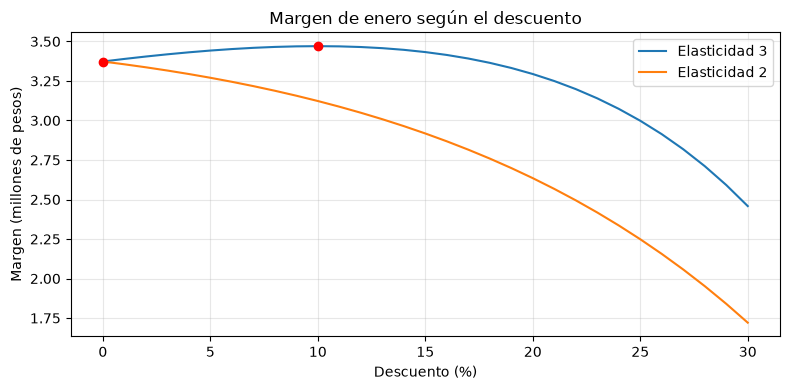

In [12]:
for eps, sim in [(3, sim3), (2, simular(2, descuentos))]:
    mejor = sim.loc[sim["margen"].idxmax()]
    base = sim.loc[0, "margen"]
    print(f"Elasticidad {eps}: descuento óptimo {mejor['descuento_pct']:.0f} %, "
          f"margen {mejor['margen'] / 1e6:.3f} millones "
          f"({(mejor['margen'] / base - 1) * 100:+.1f} % frente a no descontar)")

sim2 = simular(2, descuentos)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sim3["descuento_pct"], sim3["margen"] / 1e6, label="Elasticidad 3")
ax.plot(sim2["descuento_pct"], sim2["margen"] / 1e6, label="Elasticidad 2")
for sim in (sim3, sim2):
    mejor = sim.loc[sim["margen"].idxmax()]
    ax.scatter(mejor["descuento_pct"], mejor["margen"] / 1e6, color="red", zorder=3)
ax.set_title("Margen de enero según el descuento")
ax.set_xlabel("Descuento (%)")
ax.set_ylabel("Margen (millones de pesos)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación.** Con $
arepsilon = 3$, el margen máximo se alcanza con un **descuento del 10 %**: 3.470 millones frente a 3.373 millones sin descuento (+2.9 %). Coincide con el resultado teórico: con elasticidad constante, el precio que maximiza el margen es $p^* = c\,
arepsilon/(
arepsilon - 1) = 1.5\,c = 0.9\,p_0$. A partir del 10 %, cada punto adicional de descuento reduce el margen, y con 30 % cae a 2.458 millones.

Con $
arepsilon = 2$, la recomendación cambia: el óptimo es **no descontar** (0 %), y cualquier descuento reduce el margen. En ese caso $p^* = 2c = 1.2\,p_0$: el precio óptimo estaría por encima del precio actual, así que rebajarlo solo regala margen. La recomendación prescriptiva depende por completo de un supuesto, la elasticidad, que hoy nadie ha medido.

**Recomendación para la dirección:**

1. Antes de lanzar un descuento general, medir la elasticidad con una prueba controlada, por ejemplo un 10 % en una región durante dos semanas, comparada con las demás.
2. Si la elasticidad resulta cercana a 3, un descuento del 10 % maximiza el margen, pero la ganancia es pequeña (+2.9 %) y exige atender un 37 % más de pedidos (14 144 frente a 10 311). Un 5 % logra la mayor parte de esa ganancia (+2.1 %) con un 17 % más de pedidos (12 026), una opción más prudente para la logística.
3. En cualquier caso, resolver primero las entregas en Norte: un aumento de pedidos con entregas de 6 días agravaría el problema que encontramos en la Tarea 4.

## Conclusiones

- Los cuatro tipos de analítica forman una cadena: la descriptiva mostró que la conversión bajó desde septiembre, la diagnóstica encontró por qué (entregas más lentas en Norte), la predictiva estimó enero y la prescriptiva recomendó una acción.
- Recuperar las entregas en Norte es probablemente la acción más valiosa: su conversión cayó de 2.07 % a 1.46 % y sus ingresos, un 31.7 %, mientras las visitas seguían creciendo.
- El pronóstico de unos 8.70 millones para enero es solo una referencia: se basa en 12 meses, sin estacionalidad y con una caída regional que distorsiona la tendencia.
- El descuento óptimo depende de la elasticidad: 10 % si es 3 y ninguno si es 2. Medirla con una prueba controlada vale más que cualquier simulación.
- Las preguntas descriptivas y diagnósticas son trabajo del analista de datos, las predictivas y prescriptivas del científico de datos, y ambos dependen de la infraestructura que construye el ingeniero de datos.